# Agendamento de bombas da ETA — Pyomo + HiGHS

Mesmo problema do notebook `ETA_agendamento_bombas_tarifa_aneel_sp.ipynb` (MILP de 24 horas: 6 bombas, 5 reservatórios, 12 setores, tarifa horossazonal da ANEEL), mas escrito em **Pyomo** e resolvido com **HiGHS**, solver de código aberto.

**Por que migrar:** a licença restrita do Gurobi (`pip install gurobipy`) limita o modelo a cerca de 2.000 variáveis e 2.000 restrições. O caso de 1 dia (1.080 variáveis) cabe, mas horizontes maiores (2 dias ou mais) não. Com HiGHS não há esse limite.

**Como usar:** edite os parâmetros da próxima célula e execute o notebook de cima para baixo. Para abrir a tela em Tkinter, veja a última seção.

Requisitos: `pip install pyomo highspy pandas numpy matplotlib` (e o CSV `dados/tarifas-homologadas-distribuidoras-energia-eletrica.csv`, o mesmo do outro notebook).

## 1. Parâmetros do cenário

- `DEMANDA_DIARIA_M3`: demanda de **água** do dia em m³ (o consumo de energia em kWh é o **resultado** da otimização). `None` usa a demanda do cenário original, 12.787,2 m³/dia.
- `DIAS`: com mais de 1 dia a curva de demanda é repetida (o modelo cresce e o solver demora mais).
- `MIP_GAP`: margem de erro aceita. Com 1%, a solução encontrada custa no máximo 1% a mais que o ótimo verdadeiro.

In [1]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

warnings.filterwarnings("ignore")

def br(v, nd=0):
    """Formata número no padrão brasileiro (12.787,2)."""
    return f"{v:,.{nd}f}".replace(",", "X").replace(".", ",").replace("X", ".")

# ===== Parâmetros do cenário (edite aqui) =====
DISTRIBUIDORA = "ELETROPAULO"   # ELETROPAULO, EDP SP, CPFL-PAULISTA, CPFL-PIRATINING, CPFL Santa Cruz, ELEKTRO
MODALIDADE = "Verde"            # Verde ou Azul
SUBGRUPO = "A4"
DATA_REF = "2026-10-06"         # data usada para escolher a tarifa vigente
DEMANDA_DIARIA_M3 = None        # None = cenário original (12.787,2 m³/dia); ou ex.: 13500
DIAS = 1                        # horizonte em dias
MIP_GAP = 0.01                  # 1 %
LIMITE_S = 120                  # limite de tempo do solver (segundos)

## 2. Dados da ETA

Os mesmos do notebook original: potência e vazão máxima das bombas, volumes dos reservatórios, ligações bomba→reservatório e reservatório→setor, e a curva horária de demanda de verão.

In [2]:
HORAS_PONTA = (17, 18, 19)
BOMBAS = list(range(1, 7))
RESERVATORIOS = list(range(1, 6))
SETORES = list(range(1, 13))
ARCOS_PR = [(1,1),(2,1),(2,2),(2,3),(3,2),(4,3),(4,4),(5,5),(6,4),(6,5)]
ARCOS_RS = [(1,1),(1,2),(1,3),(2,2),(2,4),(2,5),(3,4),(3,6),(3,7),(4,4),(4,8),(4,9),(4,10),(4,12),
            (5,7),(5,10),(5,11),(5,12)]
PARAM_BOMBAS = {1:(60,0,150), 2:(120,0,280), 3:(70,0,150), 4:(80,0,180), 5:(50,0,120), 6:(70,0,150)}  # kW, Qmin, Qmax (m³/h)
Q_ETA_MAX = 600                                                                                       # m³/h
PARAM_RES = {1:(135,900,270), 2:(90,600,180), 3:(90,600,180), 4:(90,600,180), 5:(45,300,90)}          # Vmin, Vmax, Vini (m³)
BASE_DEMANDA = {1:20,2:30,3:25,4:40,5:25,6:20,7:35,8:30,9:20,10:45,11:25,12:18}
CURVA_VERAO = [0.8,0.5,0.3,0.4,0.6,1.0, 1.8,2.0,1.9,1.7,1.5,1.5, 1.4,1.5,1.6,1.7,1.8,2.9, 3.4,3.0,2.6,2.0,1.5,1.0]
DEMANDA_DIARIA_BASE = round(sum(BASE_DEMANDA.values()) * sum(CURVA_VERAO), 1)   # 12.787,2 m³/dia

def demanda(dias=1, fator=1.0):
    """Demanda horária por setor (m³/h). `fator` escala a curva; dias > 1 repete a curva."""
    return {(d, t): round(BASE_DEMANDA[d] * CURVA_VERAO[t % 24] * fator, 4) for d in SETORES for t in range(24 * dias)}

FATOR = (DEMANDA_DIARIA_M3 or DEMANDA_DIARIA_BASE) / DEMANDA_DIARIA_BASE
print(f"Demanda de água: {br(DEMANDA_DIARIA_BASE * FATOR, 1)} m³/dia | capacidade teórica da ETA: {br(Q_ETA_MAX*24)} m³/dia")

Demanda de água: 12.787,2 m³/dia | capacidade teórica da ETA: 14.400 m³/dia


## 3. Tarifas da ANEEL

Mesma regra do notebook original: R$/kWh = (TUSD + TE em R$/MWh) ÷ 1.000, sem tributos nem bandeiras. A função `data_efetiva` trata datas em que o CSV ainda não tem a tarifa vigente (por exemplo, reajuste ainda não publicado): usa a vigência mais recente e avisa.

In [3]:
NOME_CSV = "tarifas-homologadas-distribuidoras-energia-eletrica.csv"

def achar_csv():
    for base in [Path.cwd(), *Path.cwd().parents]:
        c = base / "dados" / NOME_CSV
        if c.is_file():
            return c
    raise FileNotFoundError(f"dados/{NOME_CSV} não encontrado a partir de {Path.cwd()}")

def carregar_csv(csv):
    df = pd.read_csv(csv, sep=";", dtype=str)
    for c in ["DatInicioVigencia", "DatFimVigencia"]:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    for c in ["VlrTUSD", "VlrTE"]:
        df[c] = pd.to_numeric(df[c].str.replace(".", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")
    return df

def _base(df, dist, mod, sub):
    return df[(df.SigAgente == dist) & (df.DscBaseTarifaria == "Tarifa de Aplicação") & (df.DscModalidadeTarifaria == mod)
              & (df.DscSubGrupo == sub) & (df.DscClasse == "Não se aplica") & (df.DscSubClasse == "Não se aplica")
              & (df.DscDetalhe == "Não se aplica") & (df.SigAgenteAcessante == "Não se aplica")]

def data_efetiva(df, dist, mod, sub, data_ref):
    ref = pd.Timestamp(data_ref)
    f = _base(df, dist, mod, sub)
    ant = f[f.DatInicioVigencia <= ref]
    if ant.empty:
        raise ValueError(f"Sem tarifa de {dist}/{mod}/{sub} até {ref.date()}")
    if (ant.DatFimVigencia >= ref).any():
        return ref, None
    u = ant.sort_values(["DatInicioVigencia", "DatFimVigencia"]).iloc[-1]
    return pd.Timestamp(u.DatInicioVigencia), (f"CSV sem tarifa vigente em {ref:%d/%m/%Y} para {dist}; usada a vigência "
                                               f"{u.DatInicioVigencia:%d/%m/%Y} a {u.DatFimVigencia:%d/%m/%Y}.")

def tarifa_aneel(df, dist, mod, sub, data):
    """(fora_ponta, ponta) em R$/kWh."""
    f = _base(df, dist, mod, sub)
    d = pd.Timestamp(data)
    f = f[(f.DatInicioVigencia <= d) & (f.DatFimVigencia >= d) & (f.DscUnidadeTerciaria == "MWh")
          & (f.NomPostoTarifario.isin(["Ponta", "Fora ponta"]))]
    v = ((f.VlrTUSD.fillna(0) + f.VlrTE.fillna(0)) / 1000).groupby(f.NomPostoTarifario).first()
    return float(v["Fora ponta"]), float(v["Ponta"])

def tarifa_demanda_kw(df, dist, mod, sub, data):
    """Tarifa de demanda (TUSD, R$/kW). Azul: ponta e fora ponta; Verde: única."""
    f = _base(df, dist, mod, sub)
    d = pd.Timestamp(data)
    f = f[(f.DatInicioVigencia <= d) & (f.DatFimVigencia >= d) & (f.DscUnidadeTerciaria == "kW")]
    p = f.groupby("NomPostoTarifario")["VlrTUSD"].first()
    return ({"ponta": float(p["Ponta"]), "fora_ponta": float(p["Fora ponta"])} if mod == "Azul"
            else {"unica": float(p["Não se aplica"])})

CSV = achar_csv()
ANEEL = carregar_csv(CSV)
data_uso, aviso = data_efetiva(ANEEL, DISTRIBUIDORA, MODALIDADE, SUBGRUPO, DATA_REF)
tarifa_fora_ponta, tarifa_ponta = tarifa_aneel(ANEEL, DISTRIBUIDORA, MODALIDADE, SUBGRUPO, data_uso)
print(f"{DISTRIBUIDORA} | {MODALIDADE} | {SUBGRUPO} | tarifa consultada em {data_uso:%d/%m/%Y}")
print(f"  Fora ponta: R$ {br(tarifa_fora_ponta, 4)}/kWh")
print(f"  Ponta:      R$ {br(tarifa_ponta, 4)}/kWh  ({br(tarifa_ponta / tarifa_fora_ponta, 2)}x o fora ponta)")
if aviso:
    print("  AVISO:", aviso)

ELETROPAULO | Verde | A4 | tarifa consultada em 06/10/2026
  Fora ponta: R$ 0,4525/kWh
  Ponta:      R$ 1,4048/kWh  (3,10x o fora ponta)


## 4. Modelo em Pyomo

Estrutura idêntica à do Gurobi:

- **Variáveis:** `x[p,t]` (bomba ligada, binária), `q[p,t]` (vazão da bomba), `fpr` (vazão bomba→reservatório), `frs` (vazão reservatório→setor), `V[r,t]` (volume).
- **Objetivo:** minimizar $\sum_{p,t} C_t \cdot P_p \cdot x_{p,t}$ (custo de energia).
- **Restrições:** vazão de cada bomba entre 0 e $Q_{max}$ quando ligada; ETA limitada a 600 m³/h; demanda de cada setor atendida exatamente; balanço de volume nos reservatórios; volume entre mínimo e máximo; volume final maior ou igual ao inicial.

In [4]:
def construir(c_fora, c_ponta, dias=1, fator_demanda=1.0, horas_ponta=HORAS_PONTA):
    T = 24 * dias
    D = demanda(dias, fator_demanda)
    C = {t: (c_ponta if (t % 24) in horas_ponta else c_fora) for t in range(T)}
    m = pyo.ConcreteModel("ETA_bombas")
    m.H = pyo.RangeSet(0, T - 1)
    m.P = pyo.Set(initialize=BOMBAS); m.R = pyo.Set(initialize=RESERVATORIOS); m.S = pyo.Set(initialize=SETORES)
    m.APR = pyo.Set(initialize=ARCOS_PR, dimen=2); m.ARS = pyo.Set(initialize=ARCOS_RS, dimen=2)

    m.x = pyo.Var(m.P, m.H, within=pyo.Binary)
    m.q = pyo.Var(m.P, m.H, within=pyo.NonNegativeReals)
    m.fpr = pyo.Var(m.APR, m.H, within=pyo.NonNegativeReals)
    m.frs = pyo.Var(m.ARS, m.H, within=pyo.NonNegativeReals)
    m.V = pyo.Var(m.R, m.H, within=pyo.NonNegativeReals)
    for r in RESERVATORIOS:                      # limites de volume como bounds das variáveis
        for t in range(T):
            m.V[r, t].setlb(PARAM_RES[r][0]); m.V[r, t].setub(PARAM_RES[r][1])

    m.obj = pyo.Objective(expr=sum(C[t] * PARAM_BOMBAS[p][0] * m.x[p, t] for p in m.P for t in m.H), sense=pyo.minimize)

    m.qmin = pyo.Constraint(m.P, m.H, rule=lambda m, p, t: m.q[p, t] >= PARAM_BOMBAS[p][1] * m.x[p, t])
    m.qmax = pyo.Constraint(m.P, m.H, rule=lambda m, p, t: m.q[p, t] <= PARAM_BOMBAS[p][2] * m.x[p, t])
    m.qsoma = pyo.Constraint(m.P, m.H, rule=lambda m, p, t: m.q[p, t] == sum(m.fpr[a, r, t] for (a, r) in ARCOS_PR if a == p))
    m.eta = pyo.Constraint(m.H, rule=lambda m, t: sum(m.q[p, t] for p in m.P) <= Q_ETA_MAX)
    m.dem = pyo.Constraint(m.S, m.H, rule=lambda m, s, t: sum(m.frs[r, d, t] for (r, d) in ARCOS_RS if d == s) == D[s, t])

    def balanco(m, r, t):
        entra = sum(m.fpr[p, rr, t] for (p, rr) in ARCOS_PR if rr == r)
        sai = sum(m.frs[rr, s, t] for (rr, s) in ARCOS_RS if rr == r)
        return m.V[r, t] == (PARAM_RES[r][2] if t == 0 else m.V[r, t - 1]) + entra - sai
    m.bal = pyo.Constraint(m.R, m.H, rule=balanco)
    m.rec = pyo.Constraint(m.R, rule=lambda m, r: m.V[r, T - 1] >= PARAM_RES[r][2])
    return m

def resolver(m, gap=MIP_GAP, limite=LIMITE_S, log=False):
    """Resolve com HiGHS. Retorna (segundos, custo, gap final, condição de término)."""
    s = pyo.SolverFactory("appsi_highs")
    s.highs_options = {"mip_rel_gap": gap, "time_limit": float(limite), "output_flag": log, "mip_heuristic_effort": 0.3}
    t0 = time.time()
    res = s.solve(m)
    ub, lb = res.problem.upper_bound, res.problem.lower_bound
    return time.time() - t0, ub, (ub - lb) / ub, str(res.solver.termination_condition)

## 5. Otimização

In [5]:
modelo = construir(tarifa_fora_ponta, tarifa_ponta, dias=DIAS, fator_demanda=FATOR)
n_var = sum(1 for _ in modelo.component_data_objects(pyo.Var))
n_bin = sum(1 for _ in modelo.x.values())
n_res = sum(1 for _ in modelo.component_data_objects(pyo.Constraint, active=True))
print(f"Modelo: {n_var} variáveis ({n_bin} binárias) e {n_res} restrições "
      f"(o Gurobi restrito aceita no máximo ~2.000 de cada)")

tempo, custo, gap_final, termino = resolver(modelo)
print(f"\nSolver HiGHS: {termino} | {br(tempo, 1)} s | gap final {br(gap_final*100, 2)}%")
print(f"Custo total de energia: R$ {br(custo, 2)}")

Modelo: 1080 variáveis (144 binárias) e 869 restrições (o Gurobi restrito aceita no máximo ~2.000 de cada)



Solver HiGHS: optimal | 19,4 s | gap final 1,00%
Custo total de energia: R$ 2.892,78


## 6. Resultados e horários de acionamento das bombas

In [6]:
T = 24 * DIAS
D = demanda(DIAS, FATOR)
linhas = []
for t in range(T):
    lig = [p for p in BOMBAS if pyo.value(modelo.x[p, t]) > 0.5]
    ponta = (t % 24) in HORAS_PONTA
    linhas.append({"Hora": f"{t:02d}:00-{t+1:02d}:00", "Faixa": "PONTA" if ponta else "fora ponta",
                   "Tarifa (R$/kWh)": tarifa_ponta if ponta else tarifa_fora_ponta,
                   "Bombas ligadas": ", ".join(map(str, lig)) or "-",
                   "Vazão (m³/h)": round(sum(pyo.value(modelo.q[p, t]) for p in BOMBAS)),
                   "Demanda (m³/h)": round(sum(D[s, t] for s in SETORES)),
                   "Potência (kW)": sum(PARAM_BOMBAS[p][0] for p in lig), "_lig": lig, "_ponta": ponta})
plano = pd.DataFrame(linhas)

kwh = plano["Potência (kW)"].sum()
kwh_ponta = plano.loc[plano._ponta, "Potência (kW)"].sum()
print(f"Energia: {br(kwh)} kWh/dia ({br(kwh_ponta)} kWh na ponta = {br(kwh_ponta/kwh*100, 1)}%)")
print(f"Potência média: {br(kwh/T)} kW | máxima: {plano['Potência (kW)'].max()} kW | custo médio: R$ {br(custo/kwh, 3)}/kWh")

def intervalos(horas):
    out, ini, ant = [], None, None
    for h in sorted(horas):
        if ini is None: ini = ant = h
        elif h == ant + 1: ant = h
        else: out.append((ini, ant + 1)); ini = ant = h
    if ini is not None: out.append((ini, ant + 1))
    return ", ".join(f"{a:02d}:00-{b:02d}:00" for a, b in out) or "-"

print("\nQuando ligar cada bomba:")
for p in BOMBAS:
    hs = [t for t in range(T) if p in plano._lig[t]]
    print(f"  Bomba {p} ({PARAM_BOMBAS[p][0]:>3} kW): {intervalos(hs)}   [{len(hs)} h]")

plano.drop(columns=["_lig", "_ponta"]).style.format({"Tarifa (R$/kWh)": "{:.4f}"}).apply(
    lambda s: ["background-color: #FFEBEE" if v == "PONTA" else "" for v in s], subset=["Faixa"])

Energia: 5.530 kWh/dia (410 kWh na ponta = 7,4%)
Potência média: 230 kW | máxima: 270 kW | custo médio: R$ 0,523/kWh

Quando ligar cada bomba:
  Bomba 1 ( 60 kW): 00:00-06:00, 07:00-10:00, 11:00-13:00, 18:00-19:00, 22:00-24:00   [14 h]
  Bomba 2 (120 kW): 01:00-04:00, 05:00-09:00, 10:00-11:00, 12:00-17:00, 18:00-19:00, 21:00-22:00, 23:00-24:00   [16 h]
  Bomba 3 ( 70 kW): 20:00-21:00   [1 h]
  Bomba 4 ( 80 kW): 00:00-01:00, 02:00-03:00, 04:00-05:00, 06:00-07:00, 09:00-12:00, 13:00-17:00, 19:00-24:00   [16 h]
  Bomba 5 ( 50 kW): 00:00-02:00, 03:00-16:00, 17:00-21:00, 22:00-23:00   [20 h]
  Bomba 6 ( 70 kW): 09:00-10:00, 11:00-12:00, 16:00-17:00, 20:00-23:00   [6 h]


,Hora,Faixa,Tarifa (R$/kWh),Bombas ligadas,Vazão (m³/h),Demanda (m³/h),Potência (kW)
0,00:00-01:00,fora ponta,0.4525,"1, 4, 5",450,266,190
1,01:00-02:00,fora ponta,0.4525,"1, 2, 5",550,166,230
2,02:00-03:00,fora ponta,0.4525,"1, 2, 4",600,100,260
3,03:00-04:00,fora ponta,0.4525,"1, 2, 5",550,133,230
4,04:00-05:00,fora ponta,0.4525,"1, 4, 5",376,200,190
5,05:00-06:00,fora ponta,0.4525,"1, 2, 5",550,333,230
6,06:00-07:00,fora ponta,0.4525,"2, 4, 5",580,599,250
7,07:00-08:00,fora ponta,0.4525,"1, 2, 5",550,666,230
8,08:00-09:00,fora ponta,0.4525,"1, 2, 5",550,633,230
9,09:00-10:00,fora ponta,0.4525,"1, 4, 5, 6",600,566,260


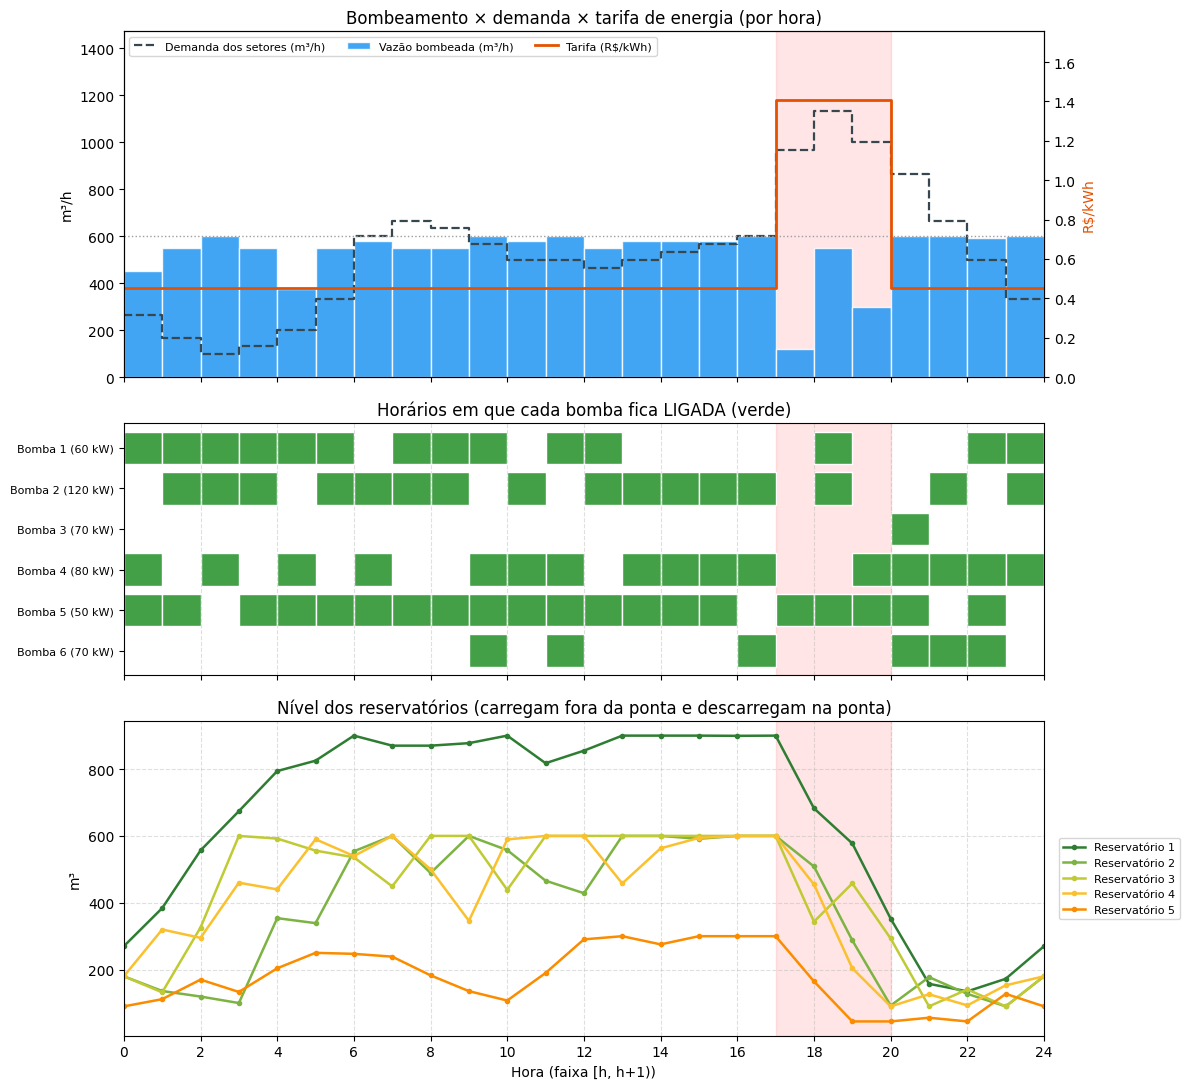

In [7]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.6, 2.0]})
x = np.arange(T)

ax1.bar(x, plano["Vazão (m³/h)"], width=1, align="edge", color="#2196F3", alpha=0.85, edgecolor="white", label="Vazão bombeada (m³/h)")
dem = plano["Demanda (m³/h)"].to_numpy()
ax1.step(np.append(x, T), np.append(dem, dem[-1]), where="post", color="#37474F", ls="--", lw=1.6, label="Demanda dos setores (m³/h)")
ax1.axhline(Q_ETA_MAX, color="#9E9E9E", ls=":", lw=1)
ax1.set_ylim(0, max(dem.max(), Q_ETA_MAX) * 1.3); ax1.set_ylabel("m³/h")
ax1.set_title("Bombeamento × demanda × tarifa de energia (por hora)")
tw = ax1.twinx(); tar = plano["Tarifa (R$/kWh)"].to_numpy()
tw.step(np.append(x, T), np.append(tar, tar[-1]), where="post", color="#E65100", lw=2, label="Tarifa (R$/kWh)")
tw.set_ylabel("R$/kWh", color="#E65100"); tw.set_ylim(0, tar.max() * 1.25)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = tw.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, ncol=3)

for p in BOMBAS:
    on = [(t, 1) for t in range(T) if p in plano._lig[t]]
    if on: ax2.broken_barh(on, (p - 0.4, 0.8), facecolors="#43A047", edgecolor="white")
ax2.set_ylim(6.6, 0.4); ax2.set_yticks(BOMBAS)
ax2.set_yticklabels([f"Bomba {p} ({PARAM_BOMBAS[p][0]} kW)" for p in BOMBAS], fontsize=8)
ax2.set_title("Horários em que cada bomba fica LIGADA (verde)"); ax2.grid(True, axis="x", ls="--", alpha=0.4)

cores = ["#2E7D32", "#7CB342", "#C0CA33", "#FBC02D", "#FB8C00"]
for i, r in enumerate(RESERVATORIOS):
    vol = [PARAM_RES[r][2]] + [pyo.value(modelo.V[r, t]) for t in range(T)]
    ax3.plot(range(T + 1), vol, marker="o", ms=3, lw=1.8, color=cores[i], label=f"Reservatório {r}")
ax3.set_ylabel("m³"); ax3.set_xlabel("Hora (faixa [h, h+1))")
ax3.set_title("Nível dos reservatórios (carregam fora da ponta e descarregam na ponta)")
ax3.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8); ax3.grid(True, ls="--", alpha=0.4)

for ax in (ax1, ax2, ax3):
    for d in range(DIAS):
        ax.axvspan(24 * d + min(HORAS_PONTA), 24 * d + max(HORAS_PONTA) + 1, color="red", alpha=0.10, zorder=0)
ax1.set_xlim(0, T); ax3.set_xticks(range(0, T + 1, 2))
plt.tight_layout(); plt.show()

## 7. Qual a demanda máxima que o modelo atende?

A capacidade teórica da ETA é 600 m³/h × 24 h = 14.400 m³/dia, mas isso só valeria se a demanda fosse constante. Como a curva de verão tem picos acima de 600 m³/h e os reservatórios guardam pouco, o máximo real é menor.

Como `Q_min = 0`, deixar todas as bombas disponíveis não restringe a viabilidade, então basta resolver um **LP** que maximiza o fator que multiplica a demanda.

In [8]:
def demanda_maxima_viavel():
    base = demanda(1, 1.0); T1 = 24
    m = pyo.ConcreteModel()
    m.f = pyo.Var(bounds=(0, 5))
    m.q = pyo.Var(BOMBAS, range(T1), bounds=(0, None))
    m.fpr = pyo.Var(ARCOS_PR, range(T1), bounds=(0, None))
    m.frs = pyo.Var(ARCOS_RS, range(T1), bounds=(0, None))
    m.V = pyo.Var(RESERVATORIOS, range(T1))
    for r in RESERVATORIOS:
        for t in range(T1):
            m.V[r, t].setlb(PARAM_RES[r][0]); m.V[r, t].setub(PARAM_RES[r][1])
    m.obj = pyo.Objective(expr=m.f, sense=pyo.maximize)
    m.c = pyo.ConstraintList()
    for p in BOMBAS:
        for t in range(T1):
            m.c.add(m.q[p, t] <= PARAM_BOMBAS[p][2])
            m.c.add(m.q[p, t] == sum(m.fpr[a, r, t] for (a, r) in ARCOS_PR if a == p))
    for t in range(T1):
        m.c.add(sum(m.q[p, t] for p in BOMBAS) <= Q_ETA_MAX)
        for s in SETORES:
            m.c.add(sum(m.frs[r, d, t] for (r, d) in ARCOS_RS if d == s) == m.f * base[s, t])
    for r in RESERVATORIOS:
        for t in range(T1):
            ent = sum(m.fpr[p, rr, t] for (p, rr) in ARCOS_PR if rr == r)
            sai = sum(m.frs[rr, s, t] for (rr, s) in ARCOS_RS if rr == r)
            m.c.add(m.V[r, t] == (PARAM_RES[r][2] if t == 0 else m.V[r, t - 1]) + ent - sai)
        m.c.add(m.V[r, T1 - 1] >= PARAM_RES[r][2])
    pyo.SolverFactory("appsi_highs").solve(m)
    return pyo.value(m.f) * DEMANDA_DIARIA_BASE

print(f"Demanda máxima atendível: {br(demanda_maxima_viavel(), 1)} m³/dia (capacidade teórica: {br(Q_ETA_MAX*24)} m³/dia)")

Demanda máxima atendível: 14.234,5 m³/dia (capacidade teórica: 14.400 m³/dia)


## 8. Cenários tarifários (distribuidoras × modalidade)

Reproduz a análise do notebook original com o HiGHS: para cada distribuidora paulista e modalidade (A4), o modelo é reconstruído com as tarifas reais e resolvido. Para ficar rápido, usa `MIPGap` de 2%.

**Atenção ao comparar Verde × Azul:** o modelo otimiza só o **custo de energia**. A demanda contratada (R$/kW) é **estimada depois**, pela maior potência ligada, e não é minimizada pelo modelo. A coluna "Total estimado" soma as duas partes, mas a comparação é só indicativa.

In [9]:
DISTRIBUIDORAS_SP = ["ELETROPAULO", "EDP SP", "CPFL-PAULISTA", "CPFL-PIRATINING", "CPFL Santa Cruz", "ELEKTRO"]

def rodar_cenario(nome, mod, c_fora, c_ponta, td=None, gap=0.02):
    m = construir(c_fora, c_ponta, dias=1, fator_demanda=FATOR)
    dt, custo_c, gap_c, term = resolver(m, gap=gap, limite=60)
    kw = {t: sum(PARAM_BOMBAS[p][0] for p in BOMBAS if pyo.value(m.x[p, t]) > 0.5) for t in range(24)}
    e = sum(kw.values()); e_p = sum(kw[t] for t in HORAS_PONTA)
    kw_p = max(kw[t] for t in HORAS_PONTA); kw_f = max(v for t, v in kw.items() if t not in HORAS_PONTA)
    dem_dia = None
    if td:
        mes = td["ponta"] * kw_p + td["fora_ponta"] * kw_f if mod == "Azul" else td["unica"] * max(kw_p, kw_f)
        dem_dia = mes / 30
    return {"Distribuidora": nome, "Modalidade": mod, "Fora ponta": c_fora, "Ponta": c_ponta,
            "Energia (R$/dia)": custo_c, "kWh": e, "kWh ponta": e_p, "Demanda est. (R$/dia)": dem_dia,
            "Total est. (R$/dia)": custo_c + dem_dia if dem_dia is not None else None, "Gap (%)": gap_c * 100, "Tempo (s)": dt}

linhas = [rodar_cenario("Hipotético original", "-", 0.60, 2.80)]
for d in DISTRIBUIDORAS_SP:
    for mod in ("Verde", "Azul"):
        du, _ = data_efetiva(ANEEL, d, mod, SUBGRUPO, DATA_REF)
        cf, cp = tarifa_aneel(ANEEL, d, mod, SUBGRUPO, du)
        linhas.append(rodar_cenario(d, mod, cf, cp, tarifa_demanda_kw(ANEEL, d, mod, SUBGRUPO, du)))
cenarios = pd.DataFrame(linhas)
cenarios.style.format({"Fora ponta": "{:.4f}", "Ponta": "{:.4f}", "Energia (R$/dia)": "{:,.2f}", "kWh": "{:,.0f}",
                       "kWh ponta": "{:,.0f}", "Demanda est. (R$/dia)": "{:,.2f}", "Total est. (R$/dia)": "{:,.2f}",
                       "Gap (%)": "{:.2f}", "Tempo (s)": "{:.1f}"}, na_rep="-")

,Distribuidora,Modalidade,Fora ponta,Ponta,Energia (R$/dia),kWh,kWh ponta,Demanda est. (R$/dia),Total est. (R$/dia),Gap (%),Tempo (s)
0,Hipotético original,-,0.6000,2.8000,"4,238.00","5,560",410,-,-,1.79,1.2
1,ELETROPAULO,Verde,0.4525,1.4048,"2,893.73","5,490",430,171.36,"3,065.09",1.55,2.0
2,ELETROPAULO,Azul,0.4525,0.6330,"2,563.64","5,470",490,366.10,"2,929.74",1.20,1.5
3,EDP SP,Verde,0.4513,1.8147,"3,036.51","5,490",410,108.18,"3,144.69",0.77,3.7
4,EDP SP,Azul,0.4513,0.6311,"2,558.37","5,450",550,477.16,"3,035.52",1.22,1.9
5,CPFL-PAULISTA,Verde,0.4370,1.7834,"2,972.92","5,540",410,165.30,"3,138.22",1.55,1.9
6,CPFL-PAULISTA,Azul,0.4370,0.5960,"2,469.02","5,450",550,518.16,"2,987.18",1.11,1.3
7,CPFL-PIRATINING,Verde,0.4518,1.4573,"2,930.64","5,530",430,124.10,"3,054.74",1.99,2.5
8,CPFL-PIRATINING,Azul,0.4518,0.6424,"2,578.11","5,500",490,399.60,"2,977.71",1.64,2.6
9,CPFL Santa Cruz,Verde,0.3953,2.1984,"2,941.28","5,570",410,221.13,"3,162.41",1.88,1.1


## 9. Gurobi × HiGHS × CBC (caso de 1 dia, ELETROPAULO Verde A4, MIPGap 1%)

Tempos medidos em um computador de 1 núcleo; no seu equipamento podem ser menores.

| Solver | Tempo | Custo (R$/dia) | Gap final |
|---|---|---|---|
| Gurobi (notebook original) | cerca de 3 s | 2.883,73 | 0,97% |
| HiGHS via Pyomo (este notebook) | 17 a 32 s | 2.892,78 a 2.893,73 | 1,0% |
| CBC via python-mip | mais de 120 s | 2.888,26 | 1,46% (não atingiu 1%) |

**Leitura:**

- Os custos de Gurobi e HiGHS diferem em menos de 0,4%, dentro do `MIPGap` de 1%: são equivalentes. O melhor valor que encontrei com gap de 0,1% foi R$ 2.874,68.
- O HiGHS acha uma boa solução em cerca de 2 s. O tempo restante é gasto **provando** que o gap é menor que 1%. Com `MIP_GAP = 0.02`, o caso de 1 dia resolve em cerca de 2 s.
- O HiGHS **não tem o limite de 2.000 variáveis**: com `DIAS = 2` (2.160 variáveis) ele resolve, o que a licença restrita do Gurobi não permite. Nos meus testes chegou a 1,34% de gap em 100 s.
- O CBC ficou claramente atrás neste modelo.

## 10. Tela em Tkinter (opcional)

A pasta `pyomo_highs/` traz `eta_gui.py`, uma tela para informar a demanda de água do dia, o `MIPGap`, escolher a distribuidora e a modalidade, e ver os gráficos por hora e os horários de ligar as bombas. Ela abre em uma **janela separada** e bloqueia a célula até ser fechada. Descomente a última linha para abrir.

In [3]:
def abrir_tela():
    """Abre a tela Tkinter. Requer a pasta pyomo_highs (eta_gui.py, eta_dados.py, eta_pyomo.py) ao lado do notebook.
    Esta célula é independente: não precisa que as células anteriores tenham sido executadas."""
    import sys
    from pathlib import Path
    for base in (Path.cwd(), Path.cwd() / "pyomo_highs", Path.cwd().parent / "pyomo_highs"):
        if (base / "eta_gui.py").is_file():
            sys.path.insert(0, str(base))
            break
    else:
        raise FileNotFoundError("eta_gui.py não encontrado. Coloque a pasta pyomo_highs ao lado deste notebook.")
    from eta_gui import App
    app = App()
    if app.ok:
        app.mainloop()

abrir_tela()   # descomente para abrir a janela